In [3]:
import tensorflow as tf
from tensorflow.keras import datasets, layers, models
from tensorflow.keras.optimizers import Adam
import keras
from keras.models import Sequential, Model
from keras.layers import *
from keras.utils import Sequence
from keras.layers import Conv2D, MaxPooling2D, Conv2DTranspose
from qkeras import *

from keras.utils import Sequence
from keras.callbacks import CSVLogger
from keras.callbacks import EarlyStopping
from keras.losses import MeanSquaredError

import os
import random
from datetime import datetime
import time

import matplotlib.pyplot as plt

pi = 3.14159265359

maxval=1e9
minval=1e-9

In [4]:
import importlib
import DAE_DataGenerator

importlib.reload(DAE_DataGenerator)
from DAE_DataGenerator import OptimizedDataGenerator as DAE_optDG
#from dataprep import *
from OptimizedDataGenerator_v2 import OptimizedDataGenerator
from loss import *
from dataset_utils import add_noise
import math


In [3]:
import models
importlib.reload(models)
from models import *
# from models import CreateAutoEncoder, CreateSQAutoEncoder


weights_path = './SQ_DAE/model-20014e96-SQDAE_Conv2D_Categorical_2bit_0eN_Target_0_30_856_V2-checkpoints'
base_dir = weights_path
checkpoint_files = [os.path.join(base_dir, f) for f in os.listdir(base_dir) if f.endswith('.hdf5')]
latest_checkpoint = max(checkpoint_files, key=os.path.getmtime)
#training_cp_path = os.path.join(base_dir, 'training_log.csv')
#training_history = pd.read_csv(training_cp_path)

print(f"Loading model from {latest_checkpoint}")

model = CreateSQAE_MaxConv2DReg_fromweights((16,16,2), weights_path, FEBits = 2, OutBits = 2, n_filters=5, pool_size=3, 
                        conv_kernel_size=3, decoder_filters = 128)
model.summary()

model.compile(
    optimizer=tf.keras.optimizers.Nadam(learning_rate=1e-3),
    loss=custom_loss
)


Loading model from ./SQ_DAE/model-20014e96-SQDAE_Conv2D_Categorical_2bit_0eN_Target_0_30_856_V2-checkpoints/weights.1754-t124361.5547-v118714.4141.hdf5
Loading model from ./SQ_DAE/model-20014e96-SQDAE_Conv2D_Categorical_2bit_0eN_Target_0_30_856_V2-checkpoints/weights.1754-t124361.5547-v118714.4141.hdf5


2026-07-03 04:14:32.842568: I tensorflow/stream_executor/cuda/cuda_gpu_executor.cc:980] successful NUMA node read from SysFS had negative value (-1), but there must be at least one NUMA node, so returning NUMA node zero
2026-07-03 04:14:32.879517: I tensorflow/stream_executor/cuda/cuda_gpu_executor.cc:980] successful NUMA node read from SysFS had negative value (-1), but there must be at least one NUMA node, so returning NUMA node zero
2026-07-03 04:14:32.879896: I tensorflow/stream_executor/cuda/cuda_gpu_executor.cc:980] successful NUMA node read from SysFS had negative value (-1), but there must be at least one NUMA node, so returning NUMA node zero
2026-07-03 04:14:32.880953: I tensorflow/core/platform/cpu_feature_guard.cc:193] This TensorFlow binary is optimized with oneAPI Deep Neural Network Library (oneDNN) to use the following CPU instructions in performance-critical operations:  SSE4.1 SSE4.2 AVX AVX2 FMA
To enable them in other operations, rebuild TensorFlow with the appropri

index: 0 input_1
index: 1 soft_quantizer_output
index: 2 q_separable_conv2d
index: 3 q_activation
index: 4 q_conv2d
index: 5 q_activation_1
index: 6 average_pooling2d
index: 7 q_activation_2
index: 8 conv2d_transpose
index: 9 q_activation_3
index: 10 conv2d_transpose_1
index: 11 q_activation_4
index: 12 conv2d
index: 13 q_activation_5
index: 14 flatten
index: 15 dense
index: 16 reshape
latent space layer:  q_activation_2 (None, 4, 4, 5)
Model: "model_2"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 input_1 (InputLayer)        [(None, 16, 16, 2)]       0         
                                                                 
 soft_quantizer_output (Soft  (None, 16, 16, 2)        4         
 QuantizeLayer)                                                  
                                                                 
 q_separable_conv2d (QSepara  (None, 14, 14, 5)        33        
 bleConv2D)   

In [5]:
'''Load a previous SQDAE Conv2D model'''
import models
importlib.reload(models)
from models import *
# from models import CreateAutoEncoder, CreateSQAutoEncoder


weights_path = './SQ_DAE_regression/model-3bcca758-SQDAE_MaxConv2Dregression_Categorical2bit_0eN_Target_0_30_856-checkpoints/'
base_dir = weights_path
checkpoint_files = [os.path.join(base_dir, f) for f in os.listdir(base_dir) if f.endswith('.hdf5')]
latest_checkpoint = max(checkpoint_files, key=os.path.getmtime)
#training_cp_path = os.path.join(base_dir, 'training_log.csv')
#training_history = pd.read_csv(training_cp_path)

print(f"Loading model from {latest_checkpoint}")

model = CreateSQMaxconv2DModel(shape = (16,16,2), n_filters=5, pool_size=3, conv_kernel_size = 3)

model.load_weights(latest_checkpoint)
for layer in model.layers[:7]:
            layer.trainable = False
model.summary()

model.compile(
    optimizer=tf.keras.optimizers.Nadam(learning_rate=1e-3),
    loss=custom_loss
)

Loading model from ./SQ_DAE_regression/model-3bcca758-SQDAE_MaxConv2Dregression_Categorical2bit_0eN_Target_0_30_856-checkpoints/weights.1990-t-25442.43-v-26612.42.hdf5


2026-07-06 02:23:00.297831: I tensorflow/stream_executor/cuda/cuda_gpu_executor.cc:980] successful NUMA node read from SysFS had negative value (-1), but there must be at least one NUMA node, so returning NUMA node zero
2026-07-06 02:23:00.330176: I tensorflow/stream_executor/cuda/cuda_gpu_executor.cc:980] successful NUMA node read from SysFS had negative value (-1), but there must be at least one NUMA node, so returning NUMA node zero
2026-07-06 02:23:00.330468: I tensorflow/stream_executor/cuda/cuda_gpu_executor.cc:980] successful NUMA node read from SysFS had negative value (-1), but there must be at least one NUMA node, so returning NUMA node zero
2026-07-06 02:23:00.331229: I tensorflow/core/platform/cpu_feature_guard.cc:193] This TensorFlow binary is optimized with oneAPI Deep Neural Network Library (oneDNN) to use the following CPU instructions in performance-critical operations:  SSE4.1 SSE4.2 AVX AVX2 FMA
To enable them in other operations, rebuild TensorFlow with the appropri

Model: "model"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 input_1 (InputLayer)        [(None, 16, 16, 2)]       0         
                                                                 
 soft_quantizer_output (Soft  (None, 16, 16, 2)        4         
 QuantizeLayer)                                                  
                                                                 
 q_separable_conv2d (QSepara  (None, 14, 14, 5)        33        
 bleConv2D)                                                      
                                                                 
 q_activation (QActivation)  (None, 14, 14, 5)         0         
                                                                 
 q_conv2d (QConv2D)          (None, 14, 14, 5)         30        
                                                                 
 q_activation_1 (QActivation  (None, 14, 14, 5)        0     

In [6]:
dataset_base_dir = "/uscms/home/bweiss/nobackup/smart-pixels/"
tfrecords_base_dir = os.path.join(dataset_base_dir, "tfrecords")

# dataset_dir_train = os.path.join(dataset_base_dir, "dataset_3sr_16x16_50x12P5_parquets", 'train/')
# dataset_dir_val = os.path.join(dataset_base_dir, "dataset_3sr_16x16_50x12P5_parquets", 'test/')

dataset_dir_train = os.path.join(dataset_base_dir, "dataset_3sr_16x16_50x12P5_centeredIncidence_parquets", 'train_contained/')
dataset_dir_val = os.path.join(dataset_base_dir, "dataset_3sr_16x16_50x12P5_centeredIncidence_parquets", 'test_contained/')


# tfrecords_dir_train = os.path.join(tfrecords_base_dir, "TFR_train", '3sr_16x16_80eN_raw')
# tfrecords_dir_val   = os.path.join(tfrecords_base_dir, "TFR_val", '3sr_16x16_80eN_raw')

tfrecords_dir_train = os.path.join(tfrecords_base_dir, "TFR_train", '3srCI_16x16_0eN_raw')
tfrecords_dir_val   = os.path.join(tfrecords_base_dir, "TFR_val", '3srCI_16x16_0eN_raw')

print(dataset_dir_val)
batch_size = 5000
val_batch_size = 5000
train_file_size = 80
val_file_size = 20

/uscms/home/bweiss/nobackup/smart-pixels/dataset_3sr_16x16_50x12P5_centeredIncidence_parquets/test_contained/


In [16]:
'''CHANGE THRESHOLDS AND TO_STANDARDIZE!!'''
start_time = time.time()
validation_generator = OptimizedDataGenerator(
    dataset_base_dir = dataset_dir_val,
    file_type = "parquet",
    data_format = "3D",
    batch_size = val_batch_size,
    # optimize_batch_size = True,
    file_count = val_file_size,
    to_standardize= False,
    select_contained = True,
    log_compression = False,
    noise = [0,80], #[mean, sigma]
    min_threshold = None,
    max_threshold = None,
    
    labels_list = ['x-midplane','y-midplane','cotAlpha','cotBeta'],
    input_shape = (2,16,16), # (20,13,21),
    transpose = (0,2,3,1),
    shuffle = False, 
    files_from_end=True,

    tfrecords_dir = tfrecords_dir_val,
    use_time_stamps = [0,19],
    max_workers = 2
)
print("--- Validation generator %s seconds ---" % (time.time() - start_time))

# training generator
start_time = time.time()
training_generator = OptimizedDataGenerator(
    dataset_base_dir = dataset_dir_train,
    file_type = "parquet",
    data_format = "3D",
    batch_size = batch_size,
    log_compression = False,
    # optimize_batch_size = True,
    file_count = train_file_size,
    to_standardize= False,
    select_contained = True,
    labels_list = ['x-midplane','y-midplane','cotAlpha','cotBeta'],
    input_shape = (2,16,16), # (20,13,21),
    transpose = (0,2,3,1),
    shuffle = False, # True 
    noise = [0,80],
    # threshold = -1,
    tfrecords_dir = tfrecords_dir_train,
    use_time_stamps = [0,19],
    max_workers = 2
)

print("--- Training generator %s seconds ---" % (time.time() - start_time))

Processing Files...: 100%|██████████| 20/20 [00:05<00:00,  3.84it/s]


Directory /uscms/home/bweiss/nobackup/smart-pixels/tfrecords/TFR_val/3srCI_16x16_80eN_raw is removed...


Saving batches as TFRecords: 100%|██████████| 21/21 [00:09<00:00,  2.11it/s]


Metadata saved successfully ast /uscms/home/bweiss/nobackup/smart-pixels/tfrecords/TFR_val/3srCI_16x16_80eN_raw/metadata.json
Loading metadata from /uscms/home/bweiss/nobackup/smart-pixels/tfrecords/TFR_val/3srCI_16x16_80eN_raw/metadata.json


--- Validation generator 15.83047866821289 seconds ---


Processing Files...: 100%|██████████| 80/80 [00:20<00:00,  3.91it/s]


Directory /uscms/home/bweiss/nobackup/smart-pixels/tfrecords/TFR_train/3srCI_16x16_80eN_raw is removed...


Saving batches as TFRecords: 100%|██████████| 84/84 [00:41<00:00,  2.04it/s]


Metadata saved successfully ast /uscms/home/bweiss/nobackup/smart-pixels/tfrecords/TFR_train/3srCI_16x16_80eN_raw/metadata.json
Loading metadata from /uscms/home/bweiss/nobackup/smart-pixels/tfrecords/TFR_train/3srCI_16x16_80eN_raw/metadata.json


--- Training generator 62.71353769302368 seconds ---


In [7]:
# Loading pre-generated TFRecords
validation_generator = OptimizedDataGenerator(
    load_from_tfrecords_dir= tfrecords_dir_val,
    shuffle=False,
    seed=42,
    quantize=False,
)

training_generator = OptimizedDataGenerator(
    load_from_tfrecords_dir = tfrecords_dir_train,
    shuffle=False,
    seed=42,
    quantize=False,
)

Loading metadata from /uscms/home/bweiss/nobackup/smart-pixels/tfrecords/TFR_val/3srCI_16x16_0eN_raw/metadata.json


Loading metadata from /uscms/home/bweiss/nobackup/smart-pixels/tfrecords/TFR_train/3srCI_16x16_0eN_raw/metadata.json


tf.Tensor([ 0.30724844 -0.2138076  -0.787956   -0.2616194 ], shape=(4,), dtype=float32)
max: 24162.4
min: -3385.5


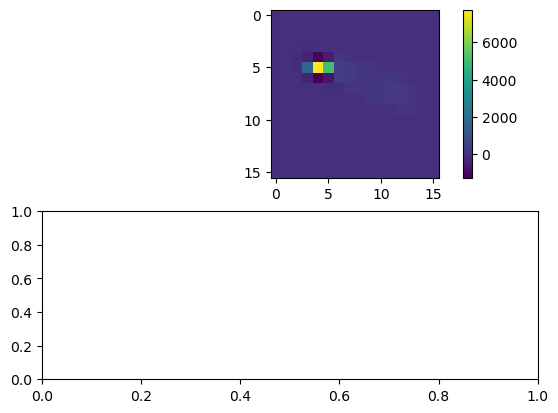

In [8]:
import matplotlib.pyplot as plt
from matplotlib import colors

n=90

cluster = training_generator[0]
# print(np.max(cluster[0].numpy()))
print(cluster[1][n])
cluster=cluster[0][:,:,:,0]

print('max:', np.max(cluster.numpy()))
print('min:', np.min(cluster.numpy()))

fig,ax = plt.subplots(2,1)
h = ax[0].imshow(cluster[n])
fig.colorbar(h)

In [9]:
from datetime import datetime
tname = 'SQDAE_MaxConv2Dregression_Categorical2bit_0eN_Target_0_30_856_V2'
fingerprint = '%08x' % random.randrange(16**8)
timestamp = datetime.now().strftime('%Y%m%d-%H%M%S')
os.makedirs("trained_models", exist_ok=True)
base_dir = f'./SQ_DAE_regression/model-{fingerprint}-{tname}-checkpoints'
os.makedirs(base_dir, exist_ok=True)  
checkpoint_filepath = base_dir + '/weights.{epoch:02d}-t{loss:.2f}-v{val_loss:.2f}.hdf5'
print(fingerprint)

b1ee0235


In [10]:
from tensorflow.keras.callbacks import CSVLogger, EarlyStopping, ModelCheckpoint, Callback

early_stopping_patience = 500

class CustomModelCheckpoint(ModelCheckpoint):
    def on_epoch_end(self, epoch, logs=None):
        super().on_epoch_end(epoch, logs)
        checkpoints = [f for f in os.listdir(base_dir) if f.startswith('weights')]
        if len(checkpoints) > 1:
            checkpoints.sort(key=lambda x: os.path.getmtime(os.path.join(base_dir,x)))
            for checkpoint in checkpoints[:-1]:
                os.remove(os.path.join(base_dir, checkpoint))

es = EarlyStopping(patience=early_stopping_patience, restore_best_weights=True)

mcp = CustomModelCheckpoint(
    filepath=checkpoint_filepath,
    save_weights_only=True,
    monitor='val_loss',
    save_best_only=True,
    save_freq='epoch',
    verbose=1
)

csv_logger = CSVLogger(f'{base_dir}/training_log.csv', append=True)

In [11]:
history = model.fit(
        x=training_generator,
        validation_data=validation_generator,
        callbacks=[es, mcp, csv_logger],
        epochs=2000,
        shuffle=False,
        verbose=1
    )

Epoch 1/2000
 2/84 [..............................] - ETA: 5s - loss: -21671.6738  

2026-07-06 02:23:30.459688: I tensorflow/stream_executor/cuda/cuda_blas.cc:1614] TensorFloat-32 will be used for the matrix multiplication. This will only be logged once.
2026-07-06 02:23:30.469766: I tensorflow/stream_executor/cuda/cuda_dnn.cc:384] Loaded cuDNN version 8800
2026-07-06 02:23:30.491825: I tensorflow/core/util/cuda_solvers.cc:179] Creating GpuSolver handles for stream 0x557da5ee09a0


84/84 [==============================] - ETA: 0s - loss: -23165.9141
Epoch 1: val_loss improved from inf to -25991.12109, saving model to ./SQ_DAE_regression/model-b1ee0235-SQDAE_MaxConv2Dregression_Categorical2bit_0eN_Target_0_30_856_V2-checkpoints/weights.01-t-23165.91-v-25991.12.hdf5
84/84 [==============================] - 16s 165ms/step - loss: -23165.9141 - val_loss: -25991.1211
Epoch 2/2000
84/84 [==============================] - ETA: 0s - loss: -23435.0137
Epoch 2: val_loss did not improve from -25991.12109
84/84 [==============================] - 7s 79ms/step - loss: -23435.0137 - val_loss: -24643.9531
Epoch 3/2000
84/84 [==============================] - ETA: 0s - loss: -24031.9609
Epoch 22: val_loss did not improve from -25991.12109
84/84 [==============================] - 7s 78ms/step - loss: -24031.9609 - val_loss: -24874.4980
Epoch 23/2000
84/84 [==============================] - ETA: 0s - loss: -23881.3027
Epoch 23: val_loss did not improve from -25991.12109
84/84 [====

IOPub message rate exceeded.
The Jupyter server will temporarily stop sending output
to the client in order to avoid crashing it.
To change this limit, set the config variable
`--ServerApp.iopub_msg_rate_limit`.

Current values:
ServerApp.iopub_msg_rate_limit=1000.0 (msgs/sec)
ServerApp.rate_limit_window=3.0 (secs)



84/84 [==============================] - ETA: 0s - loss: -25855.4160
Epoch 1239: val_loss did not improve from -27512.81445
84/84 [==============================] - 7s 78ms/step - loss: -25855.4160 - val_loss: -26310.9609
Epoch 1240/2000
84/84 [==============================] - ETA: 0s - loss: -25647.9414
Epoch 1240: val_loss did not improve from -27512.81445
84/84 [==============================] - 7s 81ms/step - loss: -25647.9414 - val_loss: -26506.1797
Epoch 1241/2000
84/84 [==============================] - ETA: 0s - loss: -26177.8516
Epoch 1241: val_loss did not improve from -27512.81445
84/84 [==============================] - 6s 76ms/step - loss: -26177.8516 - val_loss: -26301.5059
Epoch 1242/2000
84/84 [==============================] - ETA: 0s - loss: -26200.0781
Epoch 1242: val_loss did not improve from -27512.81445
84/84 [==============================] - 6s 76ms/step - loss: -26200.0781 - val_loss: -24123.0293
Epoch 1243/2000
84/84 [==============================] - ETA: 0s

IOPub message rate exceeded.
The Jupyter server will temporarily stop sending output
to the client in order to avoid crashing it.
To change this limit, set the config variable
`--ServerApp.iopub_msg_rate_limit`.

Current values:
ServerApp.iopub_msg_rate_limit=1000.0 (msgs/sec)
ServerApp.rate_limit_window=3.0 (secs)

